<div align="center">
   <span style="font-size:60px; font-weight:bold;">ATTENTION</span>
</div>


# 🧠 Introduction

This project uses the **Seaborn Attention dataset**, which comes from a psychology experiment where participants solved word puzzles (anagrams) under two different conditions:

- **Focused Attention Group 🎓** → participants worked without distractions.  
- **Divided Attention Group 📱** → participants solved puzzles while distracted.  

Each participant attempted the puzzles across multiple trials, and their **scores** were recorded.  
By analyzing these results, we can explore how attention impacts **accuracy, consistency, and overall performance**.



In [1]:
# Import libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
# load datset
data = sns.load_dataset('attention')

data

,Unnamed: 0,subject,attention,solutions,score
0,0,1,divided,1,2.0
1,1,2,divided,1,3.0
2,2,3,divided,1,3.0
3,3,4,divided,1,5.0
4,4,5,divided,1,4.0
5,5,6,divided,1,5.0
6,6,7,divided,1,5.0
7,7,8,divided,1,5.0
8,8,9,divided,1,2.0
9,9,10,divided,1,6.0


| **Column** | **Meaning** |
| --- | --- |
| **Unnamed: 0** | Index column automatically added when saving/loading the dataset. It’s just a row number, not meaningful for analysis. |
| **subject** | Participant ID — a numeric identifier for each person in the experiment. |
| **attention** | Experimental condition — whether the participant was in the *focused* or *divided* attention group. |
| **solutions** | Trial number — which attempt (1, 2, or 3) the participant was solving an anagram puzzle. |
| **score** | Performance score — number of correct solutions in that trial (continuous numeric values). |

# Exploratory Data Analysis

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  60 non-null     int64  
 1   subject     60 non-null     int64  
 2   attention   60 non-null     object 
 3   solutions   60 non-null     int64  
 4   score       60 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 2.5+ KB


In [10]:
data.describe()

,Unnamed: 0,subject,solutions,score
count,60.000000,60.000000,60.000000,60.000000
mean,29.500000,10.500000,2.000000,5.958333
std,17.464249,5.814943,0.823387,1.621601
min,0.000000,1.000000,1.000000,2.000000
25%,14.750000,5.750000,1.000000,5.000000
50%,29.500000,10.500000,2.000000,6.000000
75%,44.250000,15.250000,3.000000,7.000000
max,59.000000,20.000000,3.000000,9.000000


In [6]:
data['attention'].unique()

array(['divided', 'focused'], dtype=object)

In [7]:
data.isnull().sum()

Unnamed: 0    0
subject       0
attention     0
solutions     0
score         0
dtype: int64

In [9]:

# Group by attention condition and compute mean & median
group_stats = data.groupby("attention")["score"].agg(["mean", "median"])
print("Mean & Median by Attention Group:\n", group_stats)




# Variation (standard deviation) across participants
variation_stats = data.groupby("attention")["score"].std()
print("\nStandard Deviation by Attention Group:\n", variation_stats)

Mean & Median by Attention Group:
                mean  median
attention                  
divided    5.116667     5.0
focused    6.800000     7.0

Standard Deviation by Attention Group:
 attention
divided    1.573944
focused    1.186127
Name: score, dtype: float64


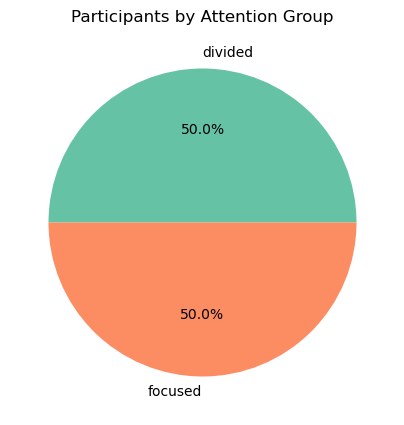

In [29]:

# Count participants in each attention group
group_counts = data["attention"].value_counts()

# Pie chart
plt.figure(figsize=(5,5))
plt.pie(group_counts, labels=group_counts.index, autopct="%1.1f%%", colors=["#66c2a5","#fc8d62"])
plt.title("Participants by Attention Group")
plt.show()

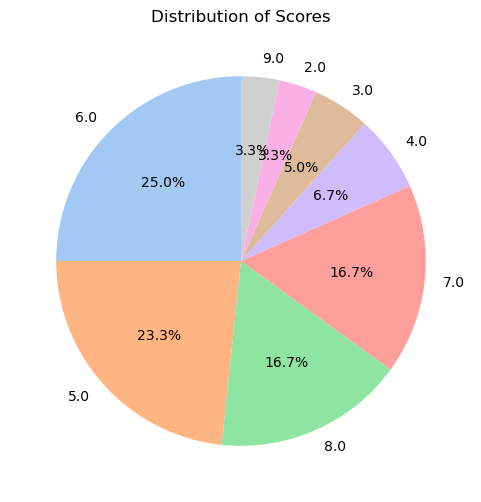

In [30]:
# Round scores to nearest integer for grouping
score_counts = data["score"].round().value_counts()

plt.figure(figsize=(6,6))
plt.pie(score_counts, labels=score_counts.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("pastel"))
plt.title("Distribution of Scores")
plt.show()


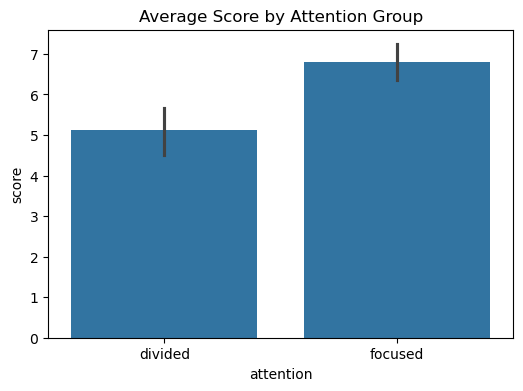

In [16]:

# 1️⃣ Bar Plot: Average score by attention group
plt.figure(figsize=(6,4))
sns.barplot(x="attention", y="score", data=data)
plt.title("Average Score by Attention Group")
plt.show()

 Focused group has higher average scores

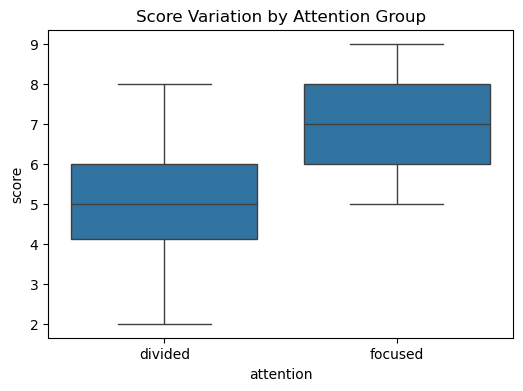

In [20]:

# 2️⃣ Box Plot: Variation in scores
plt.figure(figsize=(6,4))
sns.boxplot(x="attention", y="score", data=data)
plt.title("Score Variation by Attention Group")
plt.show()

Divided group shows more spread (less consistent)

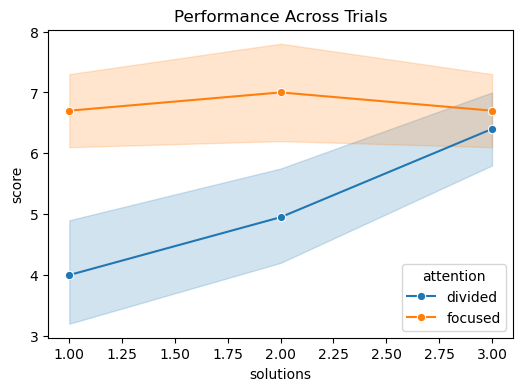

In [13]:

# 3️⃣ Line Plot: Trends across trials
plt.figure(figsize=(6,4))
sns.lineplot(x="solutions", y="score", hue="attention", data=data, marker="o")
plt.title("Performance Across Trials")
plt.show()

Focused group improves steadily across trials

<Axes: xlabel='attention', ylabel='score'>

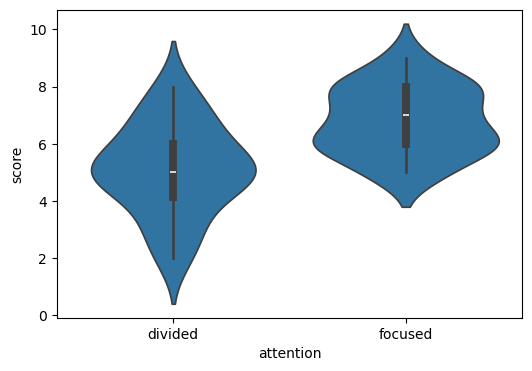

In [18]:

# 4️⃣ Violin Plot: Distribution + density
plt.figure(figsize=(6,4))
sns.violinplot(x="attention", y="score", data=data)

Density shows focused scores cluster higher

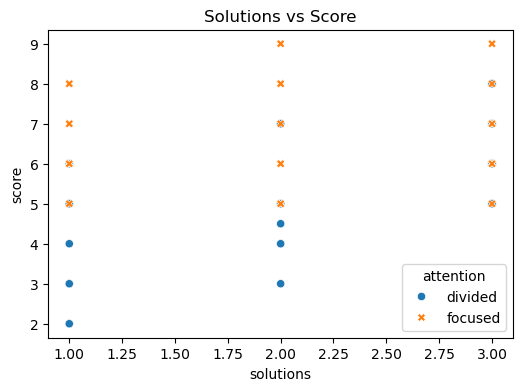

In [15]:
# 5️⃣ Scatter Plot: Relationship between solutions and score
plt.figure(figsize=(6,4))
sns.scatterplot(x="solutions", y="score", hue="attention", data=data, style="attention")
plt.title("Solutions vs Score")
plt.show()

Clear upward trend for focused participants

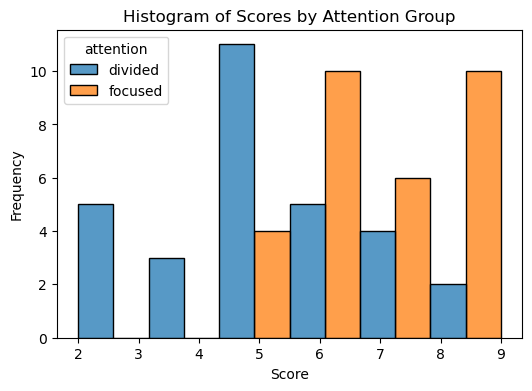

In [22]:

# Histogram of scores by attention group
plt.figure(figsize=(6,4))
sns.histplot(data=data, x="score", hue="attention", multiple="dodge", bins=6)
plt.title("Histogram of Scores by Attention Group")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()

The histogram confirms that focused attention leads to higher scores more often.

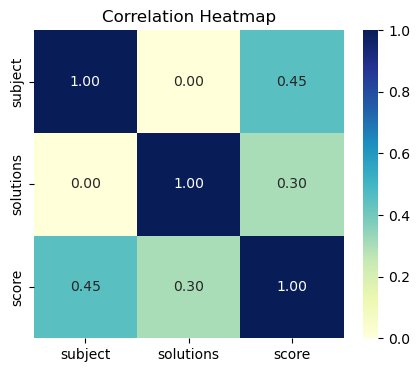

In [24]:
# Heatmap of correlations

corr = data[["subject","solutions","score"]].corr()

plt.figure(figsize=(5,4))
sns.heatmap(corr, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

The heatmap shows a positive relationship between number of trials and performance, reinforcing that practice plus focus improves outcomes

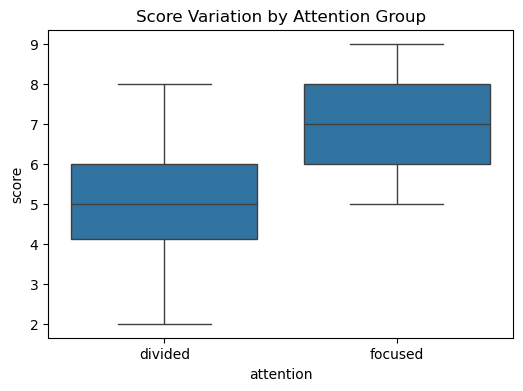

In [25]:

# Boxplot of scores by attention group
plt.figure(figsize=(6,4))
sns.boxplot(x="attention", y="score", data=data)
plt.title("Score Variation by Attention Group")
plt.show()

Focused group has tighter boxes (less variation).

Divided group shows wider spread → less consistent performance.

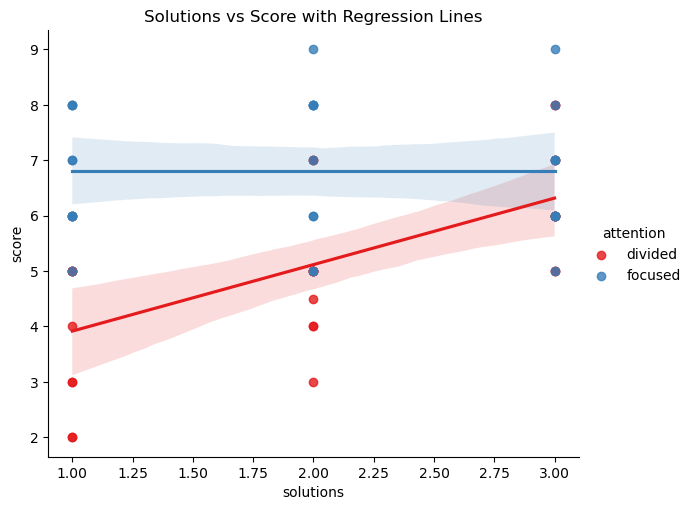

In [26]:
# lmplot: relationship between solutions and score
sns.lmplot(x="solutions", y="score", hue="attention", data=data,
           height=5, aspect=1.2, palette="Set1")
plt.title("Solutions vs Score with Regression Lines")
plt.show()


Regression lines show trend: focused group scores rise more steadily.

Divided group has flatter/sloppier trend → weaker relationship.

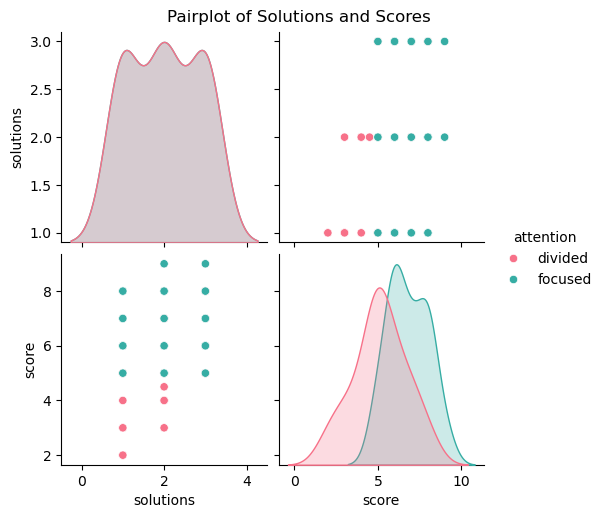

In [27]:
# Pairplot: overview of all numeric variables
sns.pairplot(data[["solutions","score","attention"]], hue="attention", palette="husl")
plt.suptitle("Pairplot of Solutions and Scores", y=1.02)
plt.show()


Confirms consistent advantage for focused attention across multiple views.

# 🎯 Conclusion


- Focus improves both **accuracy** and **consistency**.  
- Divided attention leads to **unreliable performance** and scattered results.  

**Attention is the foundation of reliable performance.  
Focused attention consistently leads to better outcomes across tasks.**
